In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate numerical data

In [ ]:
rng = np.random.default_rng(42)

X = rng.uniform(-1, 1, 200).reshape(-1, 1)
y = 3 * X[:, 0] + 2 + rng.normal(0, 0.2, 200) #y= 3x+2

print(X[:5])
print(y[:5])

[[ 0.5479121 ]
 [-0.12224312]
 [ 0.71719584]
 [ 0.39473606]
 [-0.8116453 ]]
[ 3.77240165  1.55434961  4.15056315  3.15151959 -0.367421  ]


# Split the dataset

In [6]:
indices = rng.permutation(len(X))

train_idx = indices[:160]
test_idx = indices[160:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


# Initialize the model

In [8]:
w = 0.0
b = 0.0

learning_rate = 0.1
epochs = 300
losses = []

# Train the model

In [9]:
for epoch in range(epochs):

    # Forward propagation
    y_pred = w * X_train[:, 0] + b

    # Calculate prediction error
    error = y_pred - y_train

    # Calculate loss
    loss = np.mean(error ** 2)
    losses.append(loss)

    # Calculate gradients
    dw = 2 * np.mean(error * X_train[:, 0])
    db = 2 * np.mean(error)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

print("Learned weight:", round(w, 3))
print("Learned bias:", round(b, 3))

Learned weight: 3.058
Learned bias: 2.019


# Plot the loss curve

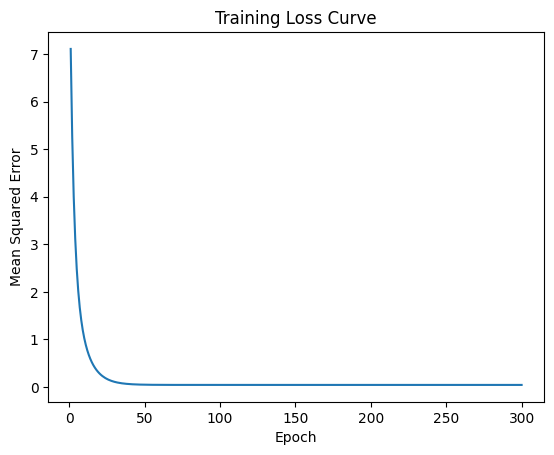

In [10]:
plt.plot(range(1, epochs + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training Loss Curve")
plt.show()

# Predict unseen inputs

In [14]:
y_pred = w * X_test[:, 0] + b

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(
        f"Actual: {actual:.3f}  "
        f"Predicted: {predicted:.3f}"
    )

Actual: 0.921  Predicted: 1.246
Actual: 0.244  Predicted: 0.587
Actual: 2.007  Predicted: 1.962
Actual: 1.844  Predicted: 1.673
Actual: 3.520  Predicted: 3.379
Actual: 3.585  Predicted: 3.616
Actual: 1.554  Predicted: 1.645
Actual: 0.416  Predicted: 0.566
Actual: 0.437  Predicted: 0.724
Actual: 4.807  Predicted: 4.844


# Evaluate model performance

In [15]:
mse = np.mean((y_test - y_pred) ** 2)

mae = np.mean(np.abs(y_test - y_pred))

r2 = 1 - (
    np.sum((y_test - y_pred) ** 2)
    / np.sum((y_test - np.mean(y_test)) ** 2)
)

print("Test MSE:", round(mse, 4))
print("Test MAE:", round(mae, 4))
print("Test R²:", round(r2, 4))

Test MSE: 0.0411
Test MAE: 0.1598
Test R²: 0.9861


# Plot actual versus predicted values

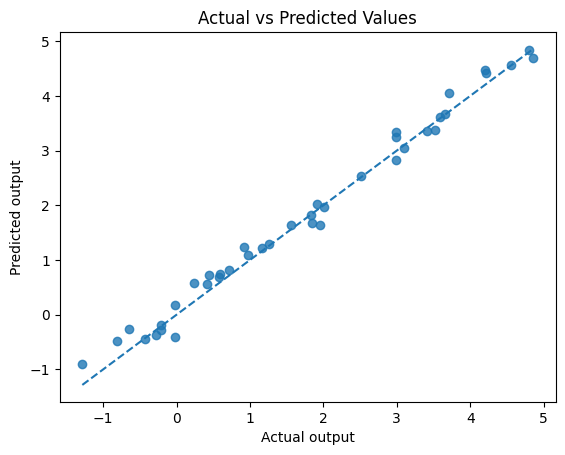

In [16]:
plt.scatter(y_test, y_pred, alpha=0.8)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "--")

plt.xlabel("Actual output")
plt.ylabel("Predicted output")
plt.title("Actual vs Predicted Values")
plt.show()